# Formative 3 — Probability Distributions, Bayes & Gradient Descent
**Group:** _Formative 3 Group 25_  <br> 
**Group Members:**  <br> 
 _Teta Nelly_ ,  <br>
 _Elie Kuradusenge_ ,  <br>
_Fabrice Mbarushimana_

All logic lives in `src/` (modular, DRY); this notebook only calls it and shows results.

<a target="_blank" href="https://colab.research.google.com/github/elkuradusenge/Probability_Distributions_Cohort3_Team25/blob/master/Formative3_Notebook.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

**Run order.** Run the next cell first. It clones this repository, installs any missing package and `cd`s into the repo
root, so every later cell can use the relative paths `data/…`, `src/…` and `src/figures/…`. It is safe to re-run and it
also works in a local checkout, where it simply detects the existing layout.

In [ ]:
# Run me first: fetch the repo, install what is missing, and make src/ importable.
import importlib.util
import os
import shutil
import subprocess
import sys
import tarfile
import urllib.request

OWNER, REPO = "elkuradusenge", "Probability_Distributions_Cohort3_Team25"
BRANCH      = "master"
REPO_URL    = f"https://github.com/{OWNER}/{REPO}.git"
TARBALL_URL = f"https://codeload.github.com/{OWNER}/{REPO}/tar.gz/refs/heads/{BRANCH}"
PACKAGES    = ["numpy", "pandas", "scipy", "matplotlib"]

IN_COLAB = "google.colab" in sys.modules or os.path.isdir("/content")


def cwd():
    """os.getcwd() raises if the kernel's directory was deleted; callers must not crash on that."""
    try:
        return os.getcwd()
    except OSError:
        return None


def reset_cwd():
    """A deleted working directory breaks every relative path, so move somewhere that exists."""
    if cwd():
        return
    for candidate in ("/content", os.path.expanduser("~"), "/tmp"):
        if os.path.isdir(candidate) and os.access(candidate, os.W_OK | os.X_OK):
            os.chdir(candidate)
            print("working directory had been deleted; moved to", candidate)
            return
    raise RuntimeError("no usable working directory found")


def sh(cmd):
    """Run a command, echo it, and print its output. Returns True on success."""
    print("$", " ".join(cmd))
    # Keep git non-interactive: a credential prompt would hang the kernel forever.
    env = {**os.environ, "GIT_TERMINAL_PROMPT": "0", "GIT_ASKPASS": "echo"}
    try:
        proc = subprocess.run(cmd, capture_output=True, text=True, env=env)
    except OSError as exc:                       # e.g. git is not installed
        print("could not run:", exc)
        return False
    print(((proc.stdout or "") + (proc.stderr or "")).strip())
    return proc.returncode == 0


def repo_root(path):
    """Nearest ancestor of `path` that looks like this repo (has src/ and data/), else None."""
    path = os.path.abspath(path)
    while True:
        if os.path.isdir(os.path.join(path, "src")) and os.path.isdir(os.path.join(path, "data")):
            return path
        parent = os.path.dirname(path)
        if parent == path:
            return None
        path = parent


def download_tarball(base):
    """git-free fallback: download the branch tarball and unpack it as <base>/<REPO>."""
    base = os.path.abspath(base)
    dest = os.path.join(base, REPO)
    archive = os.path.join(base, REPO + ".tar.gz")
    staging = os.path.join(base, REPO + ".unpack")
    print("$ downloading", TARBALL_URL)
    with urllib.request.urlopen(TARBALL_URL, timeout=600) as resp, open(archive, "wb") as fh:
        shutil.copyfileobj(resp, fh)
    shutil.rmtree(staging, ignore_errors=True)
    with tarfile.open(archive) as tar:
        try:
            tar.extractall(staging, filter="data")
        except TypeError:                        # Python < 3.12 has no filter argument
            tar.extractall(staging)
    shutil.rmtree(dest, ignore_errors=True)
    roots = [d for d in os.listdir(staging) if os.path.isdir(os.path.join(staging, d))]
    shutil.move(os.path.join(staging, roots[0]), dest)
    shutil.rmtree(staging, ignore_errors=True)
    os.remove(archive)


def ensure_repo(base):
    """Return a directory holding the project, cloning or downloading into `base` if needed."""
    base = os.path.abspath(base)
    existing = repo_root(base)
    if existing:
        print("using existing checkout:", existing)
        return existing
    dest = os.path.join(base, REPO)
    if os.path.isdir(os.path.join(dest, ".git")) and repo_root(dest):
        sh(["git", "-C", dest, "pull", "--ff-only"])       # reuse an earlier clone
    else:
        shutil.rmtree(dest, ignore_errors=True)            # drop a partial/failed clone
        if not sh(["git", "clone", "--depth", "1", "--branch", BRANCH, REPO_URL, dest]):
            download_tarball(base)                         # git blocked? fetch the tarball
    if not repo_root(dest):
        shutil.rmtree(dest, ignore_errors=True)
        download_tarball(base)
    return dest


reset_cwd()

try:
    target = ensure_repo(cwd())
except Exception as exc:
    # Read-only working directory (common when the notebook runs from a temporary
    # location): retry somewhere writable instead of giving up.
    fallback = os.path.join(os.path.expanduser("~"), "formative3")
    print("setup failed in", cwd(), "->", repr(exc))
    print("retrying in", fallback)
    os.makedirs(fallback, exist_ok=True)
    target = ensure_repo(fallback)

if not os.path.isdir(target):
    raise RuntimeError(f"could not obtain the repository (expected at {target})")
os.chdir(target)

# Colab already ships these; reinstalling can force a runtime restart, so only fill gaps.
missing = [p for p in PACKAGES if importlib.util.find_spec(p) is None]
if missing:
    if not sh([sys.executable, "-m", "pip", "install", "-q", *missing]):
        raise RuntimeError("could not install: " + ", ".join(missing))
else:
    print("packages already available:", ", ".join(PACKAGES))

os.makedirs("src/figures", exist_ok=True)      # plots are written beside the committed PNGs
src_dir = os.path.abspath("src")
if src_dir not in sys.path:
    sys.path.insert(0, src_dir)

for rel in ("data/GaltonFamilies.csv", "data/IMDB_Dataset.csv"):
    print("ok     " if os.path.exists(rel) else "MISSING", rel)
print("\ncwd:", cwd(), "| colab runtime:", IN_COLAB)

In [ ]:

import sys, numpy as np, pandas as pd
sys.path.insert(0, "src")
import em_gmm as em, bayes, gradient_descent as gd, plotting as viz
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

## Part 1 — Mixture of two Gaussians with EM (from scratch)
**Data:** Galton heights. Unlabelled pool = every child height (934) + one mother height per family (205, de-duplicated so a
mother is not counted once per child). We *hide* the labels and let EM find two Gaussians.

In [2]:
g = pd.read_csv("data/GaltonFamilies.csv")
children = g.childHeight.values
mothers  = g.drop_duplicates("family").mother.values
x = np.concatenate([children, mothers])
true_is_child = np.r_[np.ones(len(children)), np.zeros(len(mothers))]   # kept ONLY for after-the-fact evaluation
print(len(children), "children +", len(mothers), "mothers =", len(x), "heights;  global mean =", round(x.mean(), 3))

934 children + 205 mothers = 1139 heights;  global mean = 66.252


### Why not just split at the global mean?
A hard cut at the global mean assumes the two groups never overlap and that each side is "pure". Mothers and children overlap
heavily, so the cut (1) **misclassifies** every point on the wrong side, (2) **biases the means**: each pile's mean is pulled away
from the true group mean because the tails of the other group are inside it, (3) ignores the **different spreads and group sizes**
(it forces equal-ish variances and weights), and (4) gives no uncertainty — a height of 66.2 is treated exactly like 60 or 75.
EM instead gives **soft assignments** (responsibilities) and estimates μ, σ², π jointly by maximising the likelihood.

In [3]:
# initialisation (no labels needed): means one SD either side of the global mean, equal variance, equal weights
mu0, var0, pi0 = [x.mean() - x.std(), x.mean() + x.std()], [x.var()] * 2, [0.5, 0.5]
mu, var, pi, hist = em.fit_em(x, mu0, var0, pi0, tol=1e-6)
print("converged after", len(hist) - 1, "iterations")

# tracking table (initial state + first two iterations, plus the final state)
rows = [h for h in hist[:3]] + [hist[-1]]
table = pd.DataFrame([{"Iteration": ("0 (init)" if h["iter"] == 0 else h["iter"]) if h is not hist[-1] or h["iter"] < 3 else f'{h["iter"]} (final)',
                       "μ1": h["mu"][0], "μ2": h["mu"][1], "σ1²": h["var"][0], "σ2²": h["var"][1],
                       "π1": h["pi"][0], "π2": h["pi"][1], "Log-Likelihood": h["ll"]} for h in rows])
table

converged after 376 iterations


,Iteration,μ1,μ2,σ1²,σ2²,π1,π2,Log-Likelihood
0,0 (init),62.7052,69.7989,12.5802,12.5802,0.5000,0.5000,-3190.3325
1,1,64.0693,68.5283,6.5015,8.7695,0.5105,0.4895,-3041.3709
2,2,64.0394,68.5861,6.0192,8.8886,0.5133,0.4867,-3039.7574
3,376 (final),64.2993,69.7856,5.7935,5.4747,0.6441,0.3559,-3035.7484


**Reading the table.** Component 1 = the *shorter* Gaussian, Component 2 = the *taller* one. EM was never told who is a mother
or a child, so it names clusters by height, not by role (see the check below).

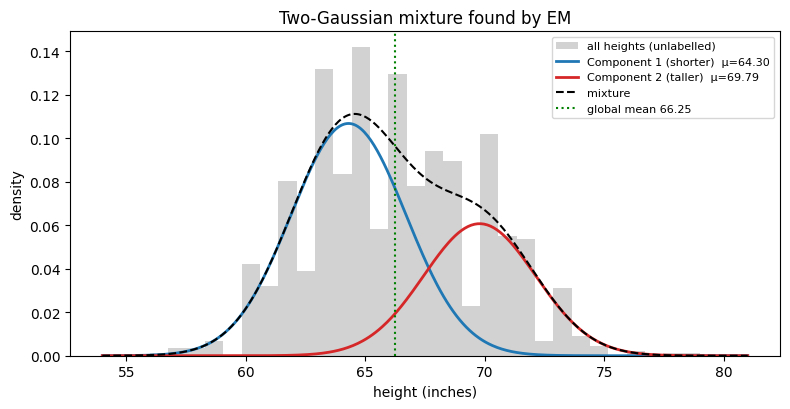

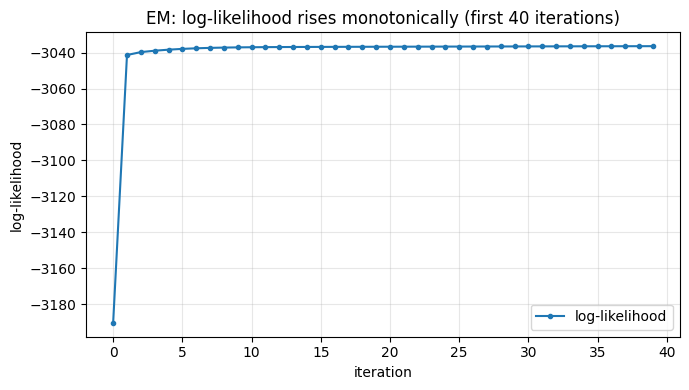

In [4]:
viz.plot_mixture(x, mu, var, pi, ["Component 1 (shorter)", "Component 2 (taller)"],
                 "Two-Gaussian mixture found by EM", path="src/figures/em_fit.png")
viz.plot_lines([h["iter"] for h in hist[:40]], [[h["ll"] for h in hist[:40]]], ["log-likelihood"],
               "EM: log-likelihood rises monotonically (first 40 iterations)", "log-likelihood", path="src/figures/em_ll.png")

### Classification demo — exact posteriors for a test height

In [5]:
def classify(h):
    p = em.posterior(h, mu, var, pi)
    print(f"Height {h} in:  P(Component 1, shorter) = {p[0]:.4f}   P(Component 2, taller) = {p[1]:.4f}   -> sum = {p.sum():.1f}")
    return p
TEST_HEIGHT = 66.0          # <- coach's height goes here
classify(TEST_HEIGHT)
for h in (60, 64, 68, 72): classify(h)

Height 66.0 in:  P(Component 1, shorter) = 0.8353   P(Component 2, taller) = 0.1647   -> sum = 1.0
Height 60 in:  P(Component 1, shorter) = 0.9996   P(Component 2, taller) = 0.0004   -> sum = 1.0
Height 64 in:  P(Component 1, shorter) = 0.9738   P(Component 2, taller) = 0.0262   -> sum = 1.0
Height 68 in:  P(Component 1, shorter) = 0.4192   P(Component 2, taller) = 0.5808   -> sum = 1.0
Height 72 in:  P(Component 1, shorter) = 0.0162   P(Component 2, taller) = 0.9838   -> sum = 1.0


### Honest check against the hidden labels
Mean-split vs EM hard assignment vs the true mother/child labels. Because **children include sons (~69 in) and daughters
(~64 in)**, the two Gaussians EM finds are "shorter people" vs "taller people", which is not exactly "mothers vs children".

In [6]:
resp = em.e_step(x, mu, var, pi)
em_comp = resp.argmax(axis=1)                                  # 0 = shorter, 1 = taller
split_comp = (x > x.mean()).astype(int)
print("Mean-split group means :", x[split_comp == 0].mean().round(3), x[split_comp == 1].mean().round(3))
print("EM component means     :", mu.round(3))
print("\nCross-tab of EM component vs true label:")
print(pd.crosstab(pd.Series(em_comp, name="EM component (0=short,1=tall)"),
                  pd.Series(np.where(true_is_child == 1, "child", "mother"), name="true label")))
print("\nSons / daughters / mothers by EM component:")
who = np.r_[g.gender.values, ["mother"] * len(mothers)]
print(pd.crosstab(pd.Series(em_comp, name="component"), pd.Series(who, name="who")))
soft = resp[:, 1]; print("\nPoints with 0.2 < P(tall) < 0.8 (genuinely ambiguous):", int(((soft > .2) & (soft < .8)).sum()), "of", len(x))

Mean-split group means : 63.576 69.472
EM component means     : [64.299 69.786]

Cross-tab of EM component vs true label:
true label                     child  mother
EM component (0=short,1=tall)               
0                                545     195
1                                389      10

Sons / daughters / mothers by EM component:
who        female  male  mother
component                      
0             421   124     195
1              32   357      10

Points with 0.2 < P(tall) < 0.8 (genuinely ambiguous): 264 of 1139


## Part 2 — Bayes' theorem on IMDb reviews (standard library only)
**Choice:** we compute **P(Positive | keyword)** only. A review "contains" a keyword if the word appears at least once
(document presence; HTML `<br />` stripped, lower-cased, word-tokenised with `re`).
Positive keywords: *excellent, wonderful, amazing, perfect* — strong, unambiguous praise words.
Negative keywords: *worst, awful, boring, waste* — strong criticism words. (Negatives should give a **low** P(Positive | kw).)

In [7]:
reviews = bayes.load_reviews("data/IMDB_Dataset.csv")      # IMDB_Dataset.csv: put the Kaggle file in data/
POS = ["excellent", "wonderful", "amazing", "perfect"]; NEG = ["worst", "awful", "boring", "waste"]
tab = pd.DataFrame(bayes.keyword_table(reviews, POS + NEG)).set_index("keyword")
tab.columns = ["Prior P(Pos)", "Likelihood P(kw|Pos)", "Marginal P(kw)", "Posterior P(Pos|kw)", "Direct count check", "# reviews with kw"]
tab

,Prior P(Pos),Likelihood P(kw|Pos),Marginal P(kw),Posterior P(Pos|kw),Direct count check,# reviews with kw
keyword,,,,,,
excellent,0.5000,0.1146,0.0710,0.8073,0.8073,3549
wonderful,0.5000,0.0902,0.0555,0.8120,0.8120,2777
amazing,0.5000,0.0671,0.0431,0.7783,0.7783,2156
perfect,0.5000,0.0815,0.0532,0.7664,0.7664,2658
worst,0.5000,0.0164,0.0886,0.0924,0.0924,4428
awful,0.5000,0.0112,0.0575,0.0977,0.0977,2875
boring,0.5000,0.0236,0.0610,0.1938,0.1938,3049
waste,0.5000,0.0070,0.0507,0.0687,0.0687,2533


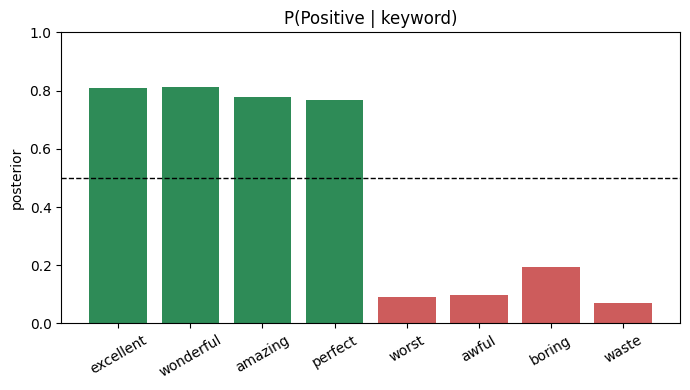

In [8]:
viz.plot_bars(tab.index, tab["Posterior P(Pos|kw)"], "P(Positive | keyword)", "posterior",
              ["seagreen"] * 4 + ["indianred"] * 4, path="src/figures/bayes.png")
# sanity: Bayes result equals the direct frequency
assert np.allclose(tab["Posterior P(Pos|kw)"], tab["Direct count check"])

**Interpretation.** With a 50/50 prior, "excellent" raises P(Positive) to ≈0.81 and "waste" drops it to ≈0.07. The likelihoods
are small (a given word appears in few reviews) but the *ratio* likelihood/marginal is what moves the prior.

## Part 3 — Manual gradient descent (see PDF) and Part 4 — in code
Same problem: ŷ = X m + b·1, X = [[1,3],[4,10]], y = [5,6], m₀ = [-1,2], b₀ = 1, α = 0.01.
The hand calculations are in **`part3_gradient_descent_calculations.pdf`**; here they are reproduced step by step.

In [9]:
X = np.array([[1, 3], [4, 10]], float); y = np.array([5, 6], float)
m0, b0, LR = np.array([-1.0, 2.0]), 1.0, 0.01
y_hat = gd.predict(X, m0, b0); err = y_hat - y
print("ŷ  =", y_hat, "\nerror =", err, "\nJ =", gd.mse(X, y, m0, b0))
gm, gb = gd.analytic_gradient(X, y, m0, b0)
print("analytic  ∇m =", gm, " ∂b =", gb)
# SciPy derivative of the cost function as an independent check
cost = lambda p: gd.mse(X, y, p[:-1], p[-1])
print("SciPy     [∂m1, ∂m2, ∂b] =", gd.scipy_gradient(cost, [*m0, b0]).round(6))

ŷ  = [ 6. 17.] 
error = [ 1. 11.] 
J = 61.0
analytic  ∇m = [ 45. 113.]  ∂b = 12.0
SciPy     [∂m1, ∂m2, ∂b] = [ 45. 113.  12.]


In [10]:
N_UPDATES = 3                                                       # = number of group members
m_fin, b_fin, h5 = gd.gradient_descent(X, y, m0, b0, LR, N_UPDATES)
pd.DataFrame([{"update": r["k"], "m1": r["m"][0], "m2": r["m"][1], "b": r["b"], "J": r["cost"],
               "ŷ": np.round(r["y_hat"], 4)} for r in h5])

,update,m1,m2,b,J,ŷ
0,0,-1.0000,2.0000,1.0000,61.0000,"[6.0, 17.0]"
1,1,-1.4500,0.8700,0.8800,6.8450,"[2.04, 3.78]"
2,2,-1.3316,1.1808,0.9318,2.7238,"[3.1426, 7.4134]"
3,3,-1.3696,1.0952,0.9362,2.3904,"[2.8522, 6.4098]"


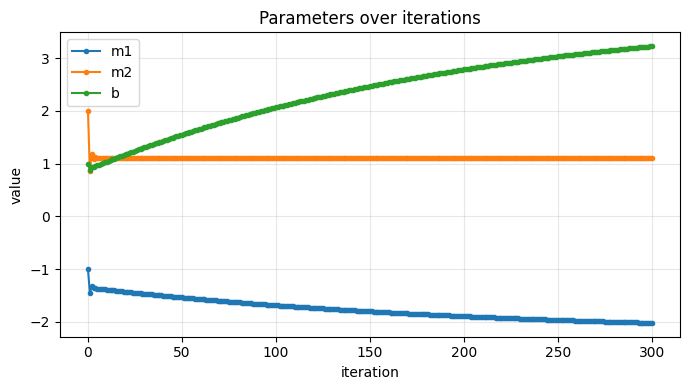

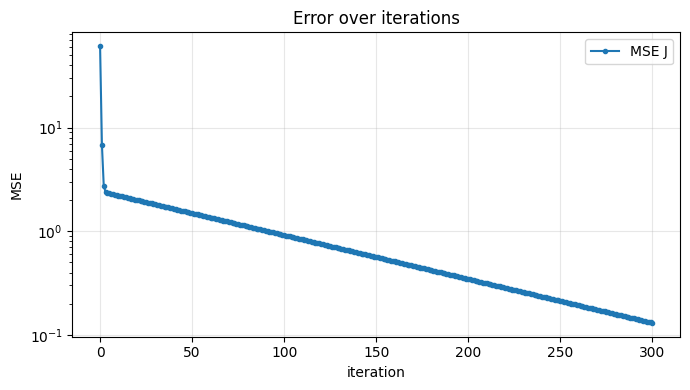

final m = [-2.0228  1.1007]  b = 3.2308  J = 0.1308
final predictions ŷ = [4.5102 6.1471] (targets [5. 6.] )


In [11]:
# longer run for the plots
M, B, H = gd.gradient_descent(X, y, m0, b0, LR, 300)
ks = [r["k"] for r in H]
viz.plot_lines(ks, [[r["m"][0] for r in H], [r["m"][1] for r in H], [r["b"] for r in H]], ["m1", "m2", "b"],
               "Parameters over iterations", "value", path="src/figures/params.png")
viz.plot_lines(ks, [[r["cost"] for r in H]], ["MSE J"], "Error over iterations", "MSE", path="src/figures/error.png", logy=True)
print("final m =", M.round(4), " b =", round(B, 4), " J =", round(H[-1]["cost"], 4))
print("final predictions ŷ =", gd.predict(X, M, B).round(4), "(targets", y, ")")

In [12]:
# cross-check against the closed-form least-squares solution
A = np.c_[X, np.ones(2)]
print("lstsq (min-norm) :", np.linalg.lstsq(A, y, rcond=None)[0].round(4))
print("GD after 300 it. :", np.r_[M, B].round(4), "-> still converging along a flat valley (X has only 2 points, 3 parameters)")

lstsq (min-norm) : [-0.9839  0.5645  4.2903]
GD after 300 it. : [-2.0228  1.1007  3.2308] -> still converging along a flat valley (X has only 2 points, 3 parameters)


**Trend.** J falls every update (61 → 6.8 → 2.7 → 2.4 → 2.3 → …). m₂ drops fast then wobbles slightly because of the
correlated features; b creeps up. With 2 samples and 3 parameters there are infinitely many exact solutions, so GD slides along a
shallow valley toward J → 0 rather than a single point.